# 4. Daily accident count regression
We aggregate collision records by date and predict the daily total from calendar fields and weather shares. To evaluate out-of-time forecasting performance realistically, we implement a chronological 2023 holdout split rather than a future-leaking random split.

Selected: Polynomial degree 2 | chronological holdout begins: 2023-05-27 | R2: 0.53


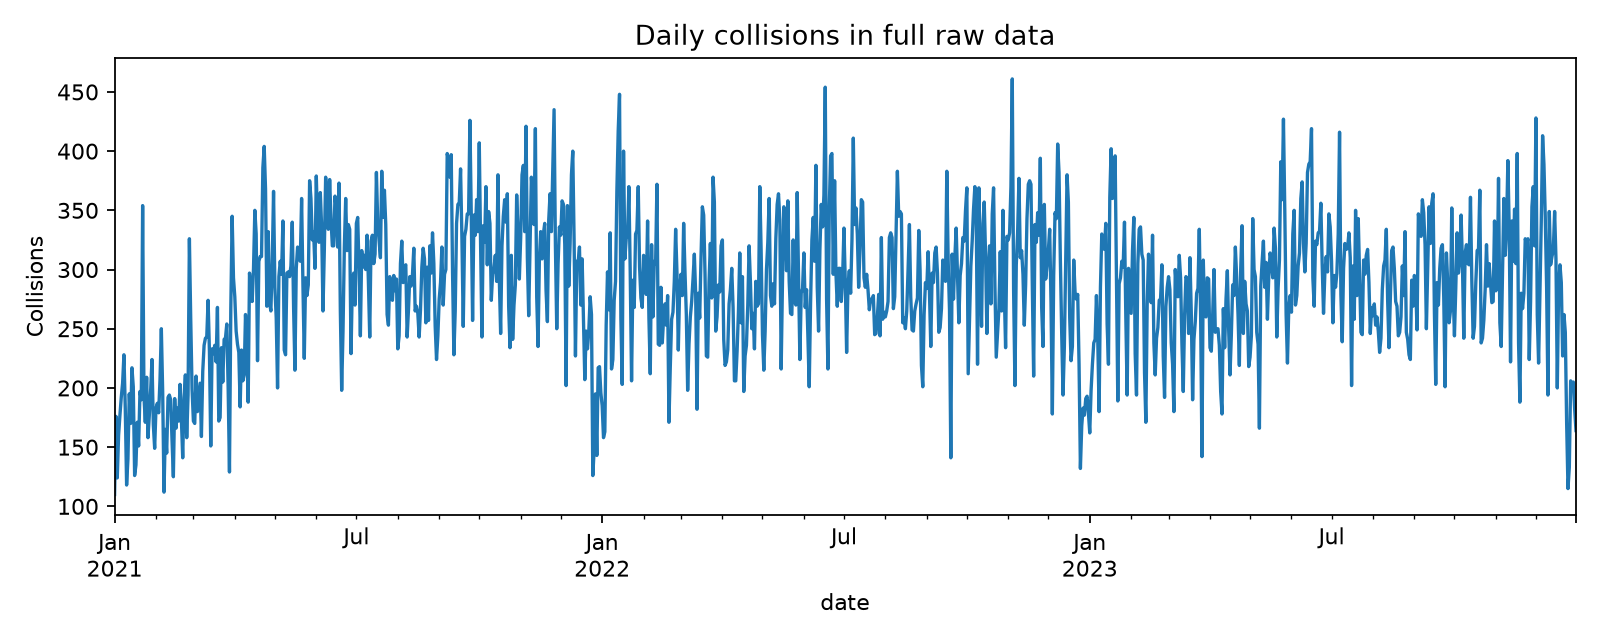

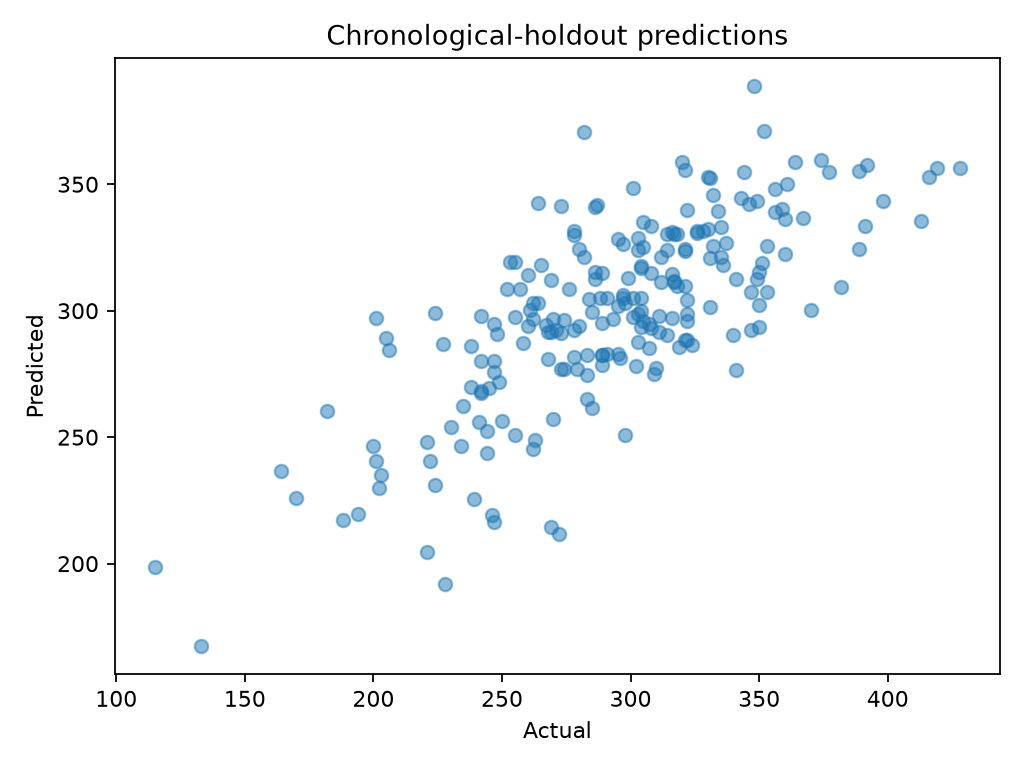

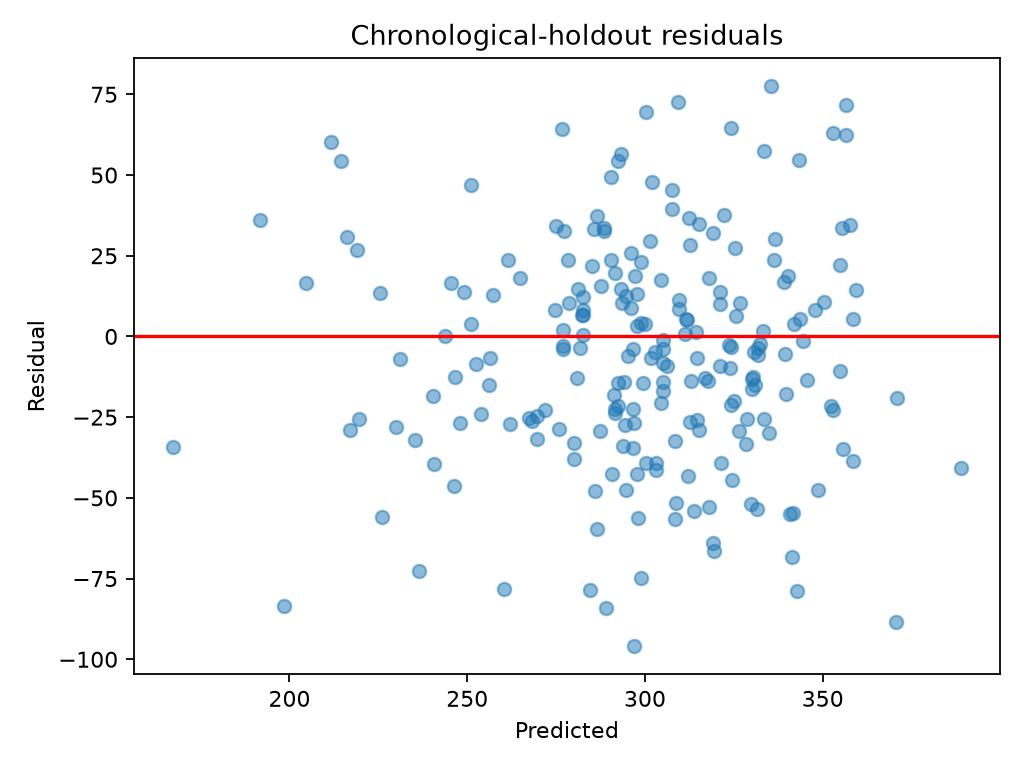

In [2]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from joblib import dump

ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
RAW = ROOT / 'data/raw'
raw_collisions = pd.concat([pd.read_csv(RAW / f'dft-road-casualty-statistics-collision-{year}.csv', low_memory=False) for year in [2021, 2022, 2023]], ignore_index=True)
raw_collisions['date'] = pd.to_datetime(raw_collisions['date'], errors='coerce', dayfirst=True)
raw_collisions['hour'] = pd.to_numeric(raw_collisions['time'].astype(str).str[:2], errors='coerce')
raw_collisions = raw_collisions[
    raw_collisions.latitude.between(49, 61) & raw_collisions.longitude.between(-9, 3) &
    raw_collisions.date.notna() & raw_collisions.hour.between(0, 23)
].copy()
raw_collisions['day'] = raw_collisions.date.dt.day_of_week
raw_collisions['month'] = raw_collisions.date.dt.month
raw_collisions['weekend'] = (raw_collisions.day >= 5).astype(int)
raw_collisions['is_night'] = raw_collisions.hour.isin([22,23,0,1,2,3,4,5])
daily = raw_collisions.groupby('date').agg(
    accidents=('collision_index', 'count'),
    day=('day', 'first'), month=('month', 'first'), weekend=('weekend', 'first'),
    rain_share=('weather_conditions', lambda x: x.isin([2, 5]).mean()),
    night_share=('is_night', 'mean')
).reset_index().sort_values('date').reset_index(drop=True)
features = ['day', 'month', 'weekend', 'rain_share', 'night_share']
cutoff = int(len(daily) * .8)
train, test = daily.iloc[:cutoff], daily.iloc[cutoff:]
X_train, y_train = train[features], train.accidents
X_test, y_test = test[features], test.accidents
models = {
    'Simple Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Multiple Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Polynomial degree 2': make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=.1, max_iter=5000))
}
rows, fits = [], {}
for name, model in models.items():
    columns = ['month'] if name == 'Simple Linear' else features
    model.fit(X_train[columns], y_train)
    pred = model.predict(X_test[columns])
    fits[name] = (model, columns, pred)
    rows.append({'model': name, 'RMSE': mean_squared_error(y_test, pred) ** .5, 'MAE': mean_absolute_error(y_test, pred), 'R2': r2_score(y_test, pred), 'correlation': np.corrcoef(y_test, pred)[0, 1], 'evaluation': 'chronological 2023 holdout'})
scores = pd.DataFrame(rows).sort_values('RMSE')
scores.to_csv(ROOT / 'outputs/tables/regression_metrics.csv', index=False)
name = scores.iloc[0].model; model, columns, pred = fits[name]
dump(model, ROOT / 'models/best_regressor.joblib')
daily.plot(x='date', y='accidents', figsize=(10,4), title='Daily collisions in full raw data', legend=False)
plt.ylabel('Collisions'); plt.tight_layout(); plt.savefig(ROOT / 'outputs/figures/daily_trend.png', dpi=160); plt.close()
plt.scatter(y_test, pred, alpha=.5); plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title('Chronological-holdout predictions')
plt.tight_layout(); plt.savefig(ROOT / 'outputs/figures/regression_actual_predicted.png', dpi=160); plt.close()
plt.scatter(pred, y_test-pred, alpha=.5); plt.axhline(0, color='red'); plt.xlabel('Predicted'); plt.ylabel('Residual')
plt.title('Chronological-holdout residuals'); plt.tight_layout(); plt.savefig(ROOT / 'outputs/figures/regression_residuals.png', dpi=160); plt.close()
print('Selected:', name, '| chronological holdout begins:', test.date.min().date(), '| R2:', round(scores.iloc[0].R2, 3))
